 # Convolutional Autoencoders

In [1]:
import keras
from keras import layers
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

### Exercise 1: Building the Autoencoder

Loading CIFAR-10. We merged back the pre-split training and testing sets and partition the dataset into:
   - **Training Set (80%):** 48,000 images
   - **Validation Set (10%):** 6,000 images
   - **Test Set (10%):** 6,000 images

We rescaled the pixel values from the original $[0, 255]$ range to $[0, 1]$.

In [2]:
# loading CIFAR-10, don't need the labels
(x_a, _), (x_b, _) = keras.datasets.cifar10.load_data()

full_cifar = np.concatenate((x_a, x_b)) # joining back the pre-split dataset into one 60k images array
rng = np.random.default_rng(42)
idx = rng.permutation(len(full_cifar))
shuffled_cifar = full_cifar[idx]
[x_train, x_val, x_test] = np.split(shuffled_cifar, [int(0.8*len(shuffled_cifar)), int(0.9*len(shuffled_cifar))])

# normalising
x_train = x_train.astype(np.float32) / 255
x_test = x_test.astype(np.float32) / 255
x_val = x_val.astype(np.float32) / 255

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2073s 12us/step


Building the autoencoder architecture

In [8]:
keras.utils.set_random_seed(42)   # same random start for every experiment
model = keras.Sequential([
    keras.Input(shape=(32,32,3)), # input image size and its 3 channels, RGB

    # Encoder: layers 1-5
    layers.Conv2D(8, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu'), # latent space representation

    # Decoder: layers 6-9
    layers.UpSampling2D(size=2),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.UpSampling2D(size=2),
    layers.Conv2D(3, kernel_size=3, padding='same', activation='sigmoid'), # inputs reconstruction
])

model.compile(optimizer="adam", loss="mse")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 8)      │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 12)     │           876 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 12)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 16)       │         1,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 12)     │         1,740 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 32, 32, 12)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 3)      │           327 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,911 (19.18 KB)

 Trainable params: 4,911 (19.18 KB)

 Non-trainable params: 0 (0.00 B)

Training autoencoder on 10 epochs

In [9]:
history = model.fit(
    x_train, x_train,                    # same input and target images
    validation_data=(x_val, x_val),
    epochs=10,
    batch_size=64,
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 54s 70ms/step - loss: 0.0136 - val_loss: 0.0079
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 50s 66ms/step - loss: 0.0072 - val_loss: 0.0069
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 65ms/step - loss: 0.0065 - val_loss: 0.0063
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 85s 69ms/step - loss: 0.0061 - val_loss: 0.0060
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 50s 67ms/step - loss: 0.0058 - val_loss: 0.0057
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 68ms/step - loss: 0.0056 - val_loss: 0.0055
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 50s 67ms/step - loss: 0.0054 - val_loss: 0.0054
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 80s 65ms/step - loss: 0.0053 - val_loss: 0.0053
Epoch 9/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 49s 65ms/step - loss: 0.0052 - val_loss: 0.0051
Epoch 10/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 50s 67ms/step - loss: 0.0051 - val_loss: 0.0051


Plotting training and validation loss across 10 epochs.

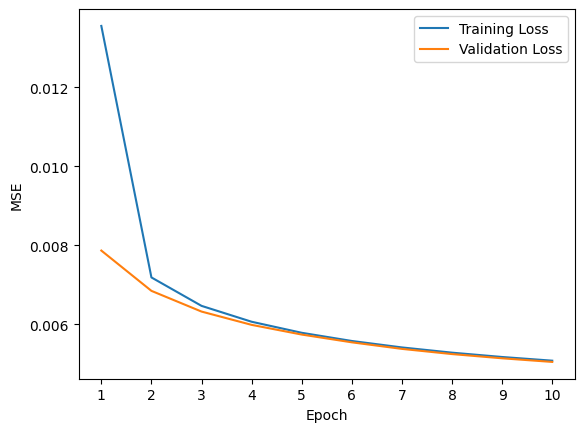

In [10]:
epochs = range(1, len(history.history["loss"]) + 1)
plt.plot(epochs, history.history["loss"], label="Training Loss")
plt.plot(epochs, history.history["val_loss"], label="Validation Loss")
plt.xticks(epochs)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

Test Mean Squared Error

In [11]:
test_mse = model.evaluate(x_test, x_test)
print("Test MSE:", test_mse)

188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0050
Test MSE: 0.00497831404209137


### Exercise 2.1: Size of the latent space representation

The latent space representation is the output of layer 5 (the convolution with 16 channels). Its size follows from applying formula (1) layer by layer:

$$W_{\text{out}} = \left\lfloor \frac{W - K + 2P}{S} \right\rfloor + 1, \qquad \text{size} = W_{\text{out}} \times W_{\text{out}} \times C$$

where $W$ is the input width and height, $K$ the kernel size, $P$ the padding, $S$ the stride and $C$ the number of channels. The convolutional layers use $K = 3$, $P = 1$, $S = 1$, and the max pooling layers use $K = 2$, $P = 0$, $S = 2$. Pooling layers keep the number of channels of their input. The input image is $32 \times 32 \times 3$.

**Layer 1: convolution, 3×3, 8 channels**

$$W_1 = \left\lfloor \frac{32 - 3 + 2 \cdot 1}{1} \right\rfloor + 1 = 31 + 1 = 32 \quad\Rightarrow\quad 32 \times 32 \times 8$$

**Layer 2: max pooling, 2×2**

$$W_2 = \left\lfloor \frac{32 - 2 + 2 \cdot 0}{2} \right\rfloor + 1 = 15 + 1 = 16 \quad\Rightarrow\quad 16 \times 16 \times 8$$

**Layer 3: convolution, 3×3, 12 channels**

$$W_3 = \left\lfloor \frac{16 - 3 + 2 \cdot 1}{1} \right\rfloor + 1 = 15 + 1 = 16 \quad\Rightarrow\quad 16 \times 16 \times 12$$

**Layer 4: max pooling, 2×2**

$$W_4 = \left\lfloor \frac{16 - 2 + 2 \cdot 0}{2} \right\rfloor + 1 = 7 + 1 = 8 \quad\Rightarrow\quad 8 \times 8 \times 12$$

**Layer 5: convolution, 3×3, 16 channels (latent space)**

$$W_5 = \left\lfloor \frac{8 - 3 + 2 \cdot 1}{1} \right\rfloor + 1 = 7 + 1 = 8 \quad\Rightarrow\quad 8 \times 8 \times 16$$

**Result**

$$\text{latent size} = 8 \times 8 \times 16 = 1024$$

The encoder compresses each image from $32 \times 32 \times 3 = 3072$ values to $1024$ values.

### Exericse 2.2: Testing different architectures

To see how the architecture affects the reconstruction error, the baseline from Exercise 1 was changed one property at a time. Every model was trained in exactly the same way: the same data split, 10 epochs, batch size 64, the Adam optimiser, MSE loss and the same random seed (42). The baseline numbers come from the Exercise 1 run. The models are compared on the validation MSE after the last epoch, and the test MSE is reported next to it.

| Experiment | Change from the baseline |
|---|---|
| latent channels 2 to 64 | Number of channels in the latent layer |
| 5x5 filters | 5×5 kernels in every convolution instead of 3×3 |
| fewer layers | One max pooling and one upsampling instead of two (6 layers) |
| more layers | A third max pooling and upsampling + 2 extra conv layers (13 layers) |
| strided convs | The max pooling layers are replaced by convolutions with stride 2 |


Two sizes are recorded for every model:

- **Latent size:** the number of values in the output of the latent layer.
- **Narrowest layer:** the smallest layer output anywhere in the network. All information has to pass through this layer, so it is the real bottleneck. In the baseline architecture this is the second max pooling layer (8 × 8 × 12 = 768 values), not the latent layer (1024 values), because the latent layer is computed from those 768 values.

In [15]:
results = []   # one dictionary per experiment (re-running this cell clears all experiments)

In [16]:
def run_experiment(name, model, epochs=10):
    model.compile(optimizer="adam", loss="mse")
    history = model.fit(
        x_train, x_train,
        validation_data=(x_val, x_val),
        epochs=epochs,
        batch_size=64,
        verbose=2,
    )
    test_mse = model.evaluate(x_test, x_test, verbose=0)

    latent_size = int(np.prod(model.get_layer("latent").output.shape[1:]))
    narrowest = min(int(np.prod(layer.output.shape[1:])) for layer in model.layers)
    val_mse = history.history["val_loss"][-1]   # validation error after the last epoch
    results.append({
        "name": name,
        "latent_size": latent_size,
        "narrowest": narrowest,
        "val_mse": val_mse,
        "test_mse": test_mse,
        "history": history.history,
    })
    print(f"{name}: latent size {latent_size}, narrowest layer {narrowest}, validation MSE {val_mse:.5f}")

In [17]:
def build_cae(latent_channels=16, kernel_size=3):
    keras.utils.set_random_seed(42)   # same random start for every model built here
    return keras.Sequential([
        keras.Input(shape=(32, 32, 3)),

        # Encoder layers
        layers.Conv2D(8, kernel_size=kernel_size, padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(12, kernel_size=kernel_size, padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(latent_channels, kernel_size=kernel_size, padding='same', activation='relu', name='latent'), # latent space representation

        # Decoder layers
        layers.UpSampling2D(size=2),
        layers.Conv2D(12, kernel_size=kernel_size, padding='same', activation='relu'),
        layers.UpSampling2D(size=2),
        layers.Conv2D(3, kernel_size=kernel_size, padding='same', activation='sigmoid'), # inputs reconstruction
    ])

In [18]:
# Reuse the Exercise 1 run instead of training the same model again
results.append({
    "name": "baseline",
    "latent_size": 8 * 8 * 16,   # 1024, from Exercise 2.1
    "narrowest": 8 * 8 * 12,     # 768, the second max pooling layer
    "val_mse": history.history["val_loss"][-1],
    "test_mse": test_mse,
    "history": history.history,
})

In [19]:
for c in [2, 4, 8, 12, 32, 64]:   # 16 channels is the baseline
    run_experiment(f"latent channels {c}", build_cae(latent_channels=c))

Epoch 1/10
750/750 - 48s - 64ms/step - loss: 0.0178 - val_loss: 0.0109
Epoch 2/10
750/750 - 45s - 60ms/step - loss: 0.0100 - val_loss: 0.0096
Epoch 3/10
750/750 - 82s - 109ms/step - loss: 0.0091 - val_loss: 0.0088
Epoch 4/10
750/750 - 46s - 61ms/step - loss: 0.0084 - val_loss: 0.0083
Epoch 5/10
750/750 - 82s - 109ms/step - loss: 0.0080 - val_loss: 0.0080
Epoch 6/10
750/750 - 46s - 61ms/step - loss: 0.0078 - val_loss: 0.0078
Epoch 7/10
750/750 - 89s - 118ms/step - loss: 0.0076 - val_loss: 0.0076
Epoch 8/10
750/750 - 78s - 104ms/step - loss: 0.0074 - val_loss: 0.0075
Epoch 9/10
750/750 - 50s - 67ms/step - loss: 0.0073 - val_loss: 0.0074
Epoch 10/10
750/750 - 80s - 107ms/step - loss: 0.0072 - val_loss: 0.0073
latent channels 2: latent size 128, narrowest layer 128, validation MSE 0.00733
Epoch 1/10
750/750 - 47s - 63ms/step - loss: 0.0150 - val_loss: 0.0086
Epoch 2/10
750/750 - 44s - 58ms/step - loss: 0.0077 - val_loss: 0.0073
Epoch 3/10
750/750 - 85s - 113ms/step - loss: 0.0069 - val_los

KeyboardInterrupt: 

In [41]:
run_experiment("5x5 filters", build_cae(kernel_size=5))

Epoch 1/10
750/750 - 16s - 22ms/step - loss: 0.0144 - val_loss: 0.0090
Epoch 2/10
750/750 - 3s - 5ms/step - loss: 0.0077 - val_loss: 0.0071
Epoch 3/10
750/750 - 3s - 4ms/step - loss: 0.0066 - val_loss: 0.0071
Epoch 4/10
750/750 - 4s - 5ms/step - loss: 0.0061 - val_loss: 0.0059
Epoch 5/10
750/750 - 3s - 5ms/step - loss: 0.0057 - val_loss: 0.0055
Epoch 6/10
750/750 - 3s - 4ms/step - loss: 0.0054 - val_loss: 0.0053
Epoch 7/10
750/750 - 3s - 4ms/step - loss: 0.0052 - val_loss: 0.0053
Epoch 8/10
750/750 - 4s - 5ms/step - loss: 0.0051 - val_loss: 0.0053
Epoch 9/10
750/750 - 3s - 4ms/step - loss: 0.0049 - val_loss: 0.0049
Epoch 10/10
750/750 - 3s - 4ms/step - loss: 0.0048 - val_loss: 0.0048
5x5 filters: latent size 1024, narrowest layer 768, validation MSE 0.00476


In [42]:
keras.utils.set_random_seed(42)   # same random start for every experiment
model = keras.Sequential([
    keras.Input(shape=(32,32,3)),

    # Encoder: one max pooling instead of two
    layers.Conv2D(8, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu', name='latent'),

    # Decoder: one upsampling instead of two
    layers.UpSampling2D(size=2),
    layers.Conv2D(3, kernel_size=3, padding='same', activation='sigmoid'),
])

run_experiment("fewer layers", model)

Epoch 1/10
750/750 - 7s - 9ms/step - loss: 0.0082 - val_loss: 0.0036
Epoch 2/10
750/750 - 3s - 4ms/step - loss: 0.0031 - val_loss: 0.0028
Epoch 3/10
750/750 - 3s - 4ms/step - loss: 0.0026 - val_loss: 0.0025
Epoch 4/10
750/750 - 3s - 4ms/step - loss: 0.0023 - val_loss: 0.0022
Epoch 5/10
750/750 - 3s - 4ms/step - loss: 0.0022 - val_loss: 0.0021
Epoch 6/10
750/750 - 3s - 4ms/step - loss: 0.0021 - val_loss: 0.0020
Epoch 7/10
750/750 - 3s - 4ms/step - loss: 0.0020 - val_loss: 0.0019
Epoch 8/10
750/750 - 3s - 5ms/step - loss: 0.0019 - val_loss: 0.0019
Epoch 9/10
750/750 - 3s - 4ms/step - loss: 0.0018 - val_loss: 0.0019
Epoch 10/10
750/750 - 3s - 4ms/step - loss: 0.0018 - val_loss: 0.0019
fewer layers: latent size 4096, narrowest layer 2048, validation MSE 0.00190


In [43]:
keras.utils.set_random_seed(42)   # same random start for every experiment
model = keras.Sequential([
    keras.Input(shape=(32,32,3)),

    # Encoder: a third max pooling, down to 4x4
    layers.Conv2D(8, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu', name='latent'),

    # Decoder: a third upsampling, back up to 32x32
    layers.UpSampling2D(size=2),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu'),
    layers.UpSampling2D(size=2),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.UpSampling2D(size=2),
    layers.Conv2D(3, kernel_size=3, padding='same', activation='sigmoid'),
])

run_experiment("more layers", model)

Epoch 1/10
750/750 - 13s - 17ms/step - loss: 0.0217 - val_loss: 0.0152
Epoch 2/10
750/750 - 3s - 4ms/step - loss: 0.0140 - val_loss: 0.0132
Epoch 3/10
750/750 - 3s - 4ms/step - loss: 0.0126 - val_loss: 0.0125
Epoch 4/10
750/750 - 3s - 4ms/step - loss: 0.0119 - val_loss: 0.0117
Epoch 5/10
750/750 - 4s - 5ms/step - loss: 0.0113 - val_loss: 0.0112
Epoch 6/10
750/750 - 3s - 4ms/step - loss: 0.0110 - val_loss: 0.0108
Epoch 7/10
750/750 - 3s - 4ms/step - loss: 0.0107 - val_loss: 0.0105
Epoch 8/10
750/750 - 3s - 4ms/step - loss: 0.0104 - val_loss: 0.0103
Epoch 9/10
750/750 - 4s - 5ms/step - loss: 0.0102 - val_loss: 0.0102
Epoch 10/10
750/750 - 5s - 6ms/step - loss: 0.0101 - val_loss: 0.0100
more layers: latent size 256, narrowest layer 256, validation MSE 0.01001


In [44]:
keras.utils.set_random_seed(42)   # same random start for every experiment
model = keras.Sequential([
    keras.Input(shape=(32,32,3)),

    # Encoder: stride 2 in the convolutions replaces the max pooling layers
    layers.Conv2D(8, kernel_size=3, strides=2, padding='same', activation='relu'),
    layers.Conv2D(12, kernel_size=3, strides=2, padding='same', activation='relu'),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu', name='latent'),

    # Decoder: same as the baseline
    layers.UpSampling2D(size=2),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.UpSampling2D(size=2),
    layers.Conv2D(3, kernel_size=3, padding='same', activation='sigmoid'),
])

run_experiment("strided convs", model)

Epoch 1/10
750/750 - 11s - 14ms/step - loss: 0.0113 - val_loss: 0.0062
Epoch 2/10
750/750 - 3s - 4ms/step - loss: 0.0056 - val_loss: 0.0052
Epoch 3/10
750/750 - 3s - 4ms/step - loss: 0.0049 - val_loss: 0.0047
Epoch 4/10
750/750 - 5s - 7ms/step - loss: 0.0046 - val_loss: 0.0045
Epoch 5/10
750/750 - 3s - 4ms/step - loss: 0.0043 - val_loss: 0.0043
Epoch 6/10
750/750 - 3s - 4ms/step - loss: 0.0041 - val_loss: 0.0041
Epoch 7/10
750/750 - 3s - 5ms/step - loss: 0.0040 - val_loss: 0.0039
Epoch 8/10
750/750 - 5s - 6ms/step - loss: 0.0038 - val_loss: 0.0038
Epoch 9/10
750/750 - 3s - 4ms/step - loss: 0.0037 - val_loss: 0.0036
Epoch 10/10
750/750 - 4s - 5ms/step - loss: 0.0036 - val_loss: 0.0035
strided convs: latent size 1024, narrowest layer 768, validation MSE 0.00353


The lowest MSE architecture to be used further

In [20]:
keras.utils.set_random_seed(42)   # same random start for every experiment
model = keras.Sequential([
    keras.Input(shape=(32,32,3)),

    # Encoder: fewer layers, with a strided convolution instead of the max pooling
    layers.Conv2D(8, kernel_size=3, strides=2, padding='same', activation='relu'),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu', name='latent'),

    # Decoder: one upsampling
    layers.UpSampling2D(size=2),
    layers.Conv2D(3, kernel_size=3, padding='same', activation='sigmoid'),
])

run_experiment("fewer layers + strided", model)

Epoch 1/10
750/750 - 37s - 50ms/step - loss: 0.0074 - val_loss: 0.0029
Epoch 2/10
750/750 - 35s - 47ms/step - loss: 0.0025 - val_loss: 0.0022
Epoch 3/10
750/750 - 35s - 47ms/step - loss: 0.0020 - val_loss: 0.0018
Epoch 4/10
750/750 - 41s - 54ms/step - loss: 0.0017 - val_loss: 0.0016
Epoch 5/10
750/750 - 35s - 47ms/step - loss: 0.0015 - val_loss: 0.0014
Epoch 6/10
750/750 - 39s - 51ms/step - loss: 0.0014 - val_loss: 0.0013
Epoch 7/10
750/750 - 40s - 53ms/step - loss: 0.0013 - val_loss: 0.0012
Epoch 8/10
750/750 - 40s - 53ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 9/10
750/750 - 41s - 54ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 10/10
750/750 - 39s - 52ms/step - loss: 0.0011 - val_loss: 0.0010
fewer layers + strided: latent size 4096, narrowest layer 2048, validation MSE 0.00105


### Comparisons between all tested architectures

In [21]:
table = pd.DataFrame(results).drop(columns="history").sort_values("val_mse")
table

,name,latent_size,narrowest,val_mse,test_mse
2,fewer layers + strided,4096,2048,0.001048,0.001029
0,baseline,1024,768,0.005054,0.004978
1,latent channels 2,128,128,0.007329,0.007241


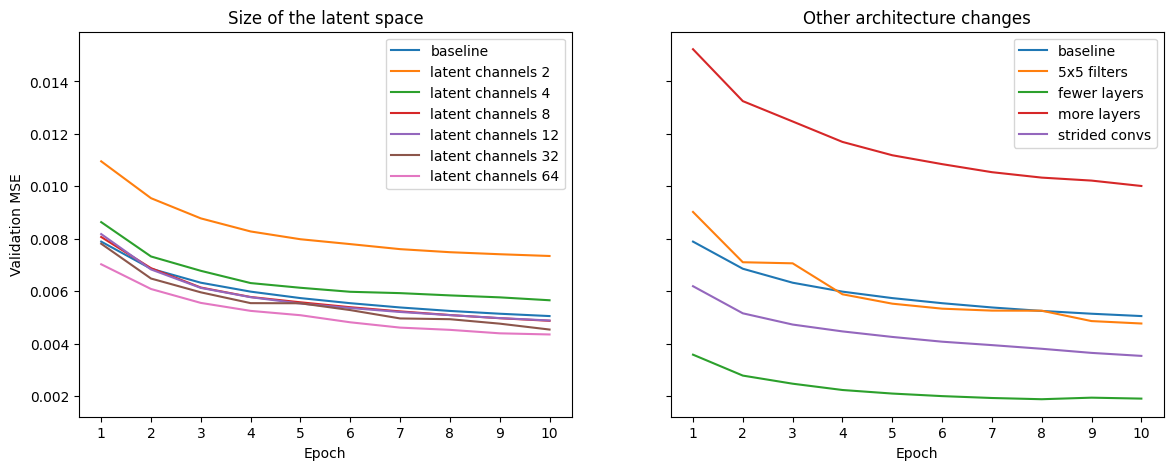

In [46]:
def in_sweep(r):   # the latent-channel runs, plus the baseline (16 channels)
    return r["name"].startswith("latent channels") or r["name"] == "baseline"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for r in results:
    epoch_numbers = range(1, len(r["history"]["val_loss"]) + 1)
    if in_sweep(r):
        ax1.plot(epoch_numbers, r["history"]["val_loss"], label=r["name"])
    if not in_sweep(r) or r["name"] == "baseline":
        ax2.plot(epoch_numbers, r["history"]["val_loss"], label=r["name"])

ax1.set_title("Size of the latent space")
ax2.set_title("Other architecture changes")
ax1.set_ylabel("Validation MSE")
for ax in (ax1, ax2):
    ax.set_xlabel("Epoch")
    ax.set_xticks(range(1, 11))
    ax.legend()
plt.show()

Architectures are ranked by validation MSE. The test MSE follows the validation MSE closely for every model, and no validation curve starts rising, so there is no sign of overfitting within 10 epochs. Most curves are still going down at epoch 10, so all errors would drop further with longer training.

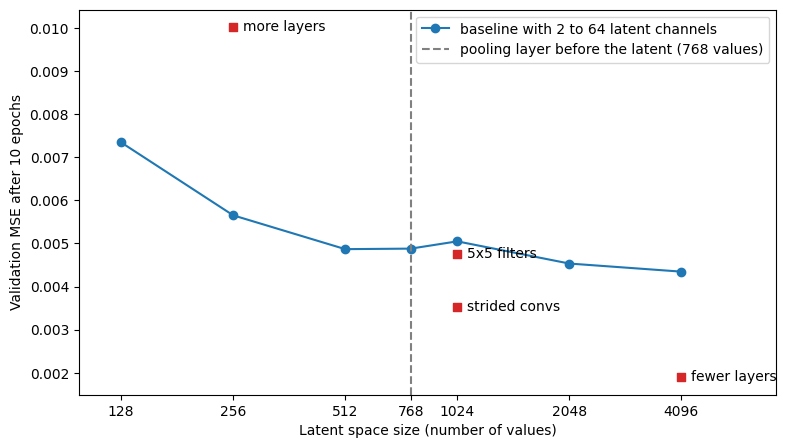

In [47]:
sweep = sorted([r for r in results if in_sweep(r)], key=lambda r: r["latent_size"])
others = [r for r in results if not in_sweep(r)]

plt.figure(figsize=(9, 5))
plt.plot([r["latent_size"] for r in sweep], [r["val_mse"] for r in sweep],
         marker="o", label="baseline with 2 to 64 latent channels")
for r in others:
    plt.scatter(r["latent_size"], r["val_mse"], marker="s", color="C3", zorder=3)
    plt.annotate(r["name"], (r["latent_size"], r["val_mse"]),
                 textcoords="offset points", xytext=(7, 0), va="center")
plt.axvline(768, linestyle="--", color="gray", label="pooling layer before the latent (768 values)")

plt.xscale("log", base=2)
sizes = sorted({r["latent_size"] for r in results})
plt.xticks(sizes, [str(s) for s in sizes])
plt.minorticks_off()
plt.xlim(sizes[0] / 1.3, sizes[-1] * 1.8)   # room for the labels on the right
plt.xlabel("Latent space size (number of values)")
plt.ylabel("Validation MSE after 10 epochs")
plt.legend()
plt.show()

**Size of the latent space.** The blue line is the baseline architecture ranging from 2 to 64 latent channels. The dashed line at 768 values splits it into two parts:

- **Left**: the latent layer is the narrowest layer. Here the error falls quickly as the latent space grows: from 0.0073 at 128 values to 0.0049 at 512 values, about a third lower.
- **Right**: the narrowest layer stays the 768-value max pooling layer before the latent layer, however many channels the latent layer gets. Making the latent space more than 5 times bigger (768 to 4096 values) lowers the error by only about 11%, and not steadily: the baseline (1024 values) is slightly worse than 512 and 768. The extra channels add weights, but no extra room for information, because everything still has to pass through the same 768 values. Differences of around 0.0002, like those between 8, 12 and 16 channels, are small enough to be run-to-run variation.

**Other architecture changes.** The red squares are the models that changed something other than the latent channels. Comparing each one with the blue point at the same latent size shows that the latent size alone does not decide the error:

- **Strided convolutions** (1024 values) reach 0.0035, ~30% lower than the baseline, even though the latent size and the narrowest layer (768) are the same. A likely reason: max pooling keeps only the largest of every four values and throws the rest away by a fixed rule, while a strided convolution learns how to combine neighbouring pixels as it downsamples, so it can keep more of the information the decoder needs.
- **5×5 filters** (1024 values) help a little: 0.0048, ~6% lower than the baseline. Each filter sees a larger area of the image and has more weights.
- **Fewer layers** (4096 values) has less than half the error of the 64-channel model with the same latent size (0.0019 against 0.0043). With only one max pooling it keeps a 16 × 16 grid instead of 8 × 8, so its narrowest layer holds 2048 values instead of 768, and the decoder only has to upsample once.
- **More layers** (256 values) has almost twice the error of the 4-channel model with the same latent size (0.0100 against 0.0057). The third max pooling shrinks the image to a 4 × 4 grid, so each latent position has to describe an 8 × 8 pixel area. The deeper network also learns more slowly: its validation curve is still clearly falling at epoch 10.


## **Is there an obvious correlation between the size of the latent space and the error?**

Only within one architecture, and only while the latent layer is the bottleneck, in which case, a larger latent space clearly gives a lower error. Across architectures there is no simple correlation. Models with the same latent size differ by more than a factor of two, because the error depends on the size of the narrowest layer and on how the network downsamples (how much spatial resolution it keeps, and max pooling or strided convolution), not on the latent layer alone.

A lower error is not automatically a better autoencoder, though. The "best model" (fewer layers one) only compresses the 3072 input values to 2048 at its narrowest point (1.5 times), while the baseline compresses them to 768 (4 times). Compressing less makes reconstruction easier, so there is a trade-off between how compact the representation is and how accurately the image can be reconstructed.

**Limitations.** Each model was trained once, for 10 epochs. Deeper models may need more epochs to catch up, and differences of around 0.0002 may be noise.

**Best configuration for Exercise 3.** An architecture with fewer layers + strided convolution has achieved the lowest validation MSE (0.001048, test MSE 0.001029).

In [3]:
# Exercise 3: grayscale inputs, colour targets
gray_weights = np.array([0.299, 0.587, 0.114], dtype=np.float32)   # how much red, green, blue

def to_gray(x):
    # x has shape (number of images, 32, 32, 3)
    # result has shape (number of images, 32, 32, 1): one brightness value per pixel
    return (x @ gray_weights)[..., np.newaxis]

g_train = to_gray(x_train)
g_val   = to_gray(x_val)
g_test  = to_gray(x_test)

print(x_train.shape, "->", g_train.shape)

(48000, 32, 32, 3) -> (48000, 32, 32, 1)


In [ ]:
keras.utils.set_random_seed(42)   
color_model = keras.Sequential([
    keras.Input(shape=(32, 32, 1)),   # grey image: 1 channel (was 3)

    # Encoder (same as the best model from Exercise 2.2)
    layers.Conv2D(8, kernel_size=3, strides=2, padding='same', activation='relu'),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu', name='latent'),

    # Decoder
    layers.UpSampling2D(size=2),
    layers.Conv2D(3, kernel_size=3, padding='same', activation='sigmoid'),   # 3 channels: R, G, B
])

color_model.compile(optimizer="adam", loss="mse")
color_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 16, 16, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 12)     │           876 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Conv2D)                 │ (None, 16, 16, 16)     │         1,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 3)      │           435 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,135 (12.25 KB)

 Trainable params: 3,135 (12.25 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
color_history = color_model.fit(
    g_train, x_train,                    # input: grey images, target: colour images
    validation_data=(g_val, x_val),
    epochs=10,
    batch_size=64,
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - loss: 0.0128 - val_loss: 0.0085
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 0.0079 - val_loss: 0.0077
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0074 - val_loss: 0.0075
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0072 - val_loss: 0.0073
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 0.0071 - val_loss: 0.0071
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 0.0069 - val_loss: 0.0070
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0069 - val_loss: 0.0070
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0068 - val_loss: 0.0069
Epoch 9/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0067 - val_loss: 0.0069
Epoch 10/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - loss: 0.0067 - val_loss: 0.0069


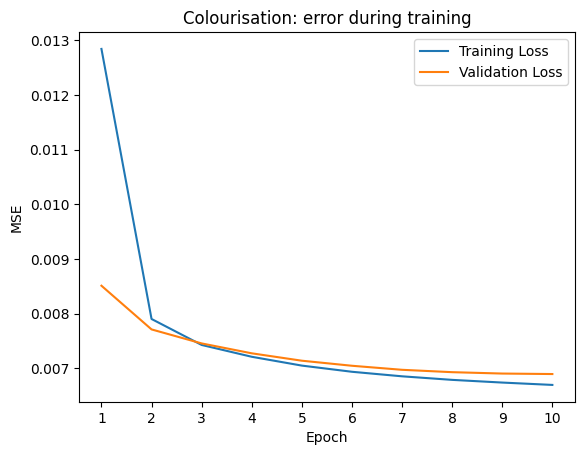

In [6]:
epochs = range(1, len(color_history.history["loss"]) + 1)
plt.plot(epochs, color_history.history["loss"], label="Training Loss")
plt.plot(epochs, color_history.history["val_loss"], label="Validation Loss")
plt.xticks(epochs)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Colourisation: error during training")
plt.legend()
plt.show()

In [7]:
color_test_mse = color_model.evaluate(g_test, x_test, verbose=0)
print("Colourisation test MSE:", color_test_mse)

Colourisation test MSE: 0.006900263484567404


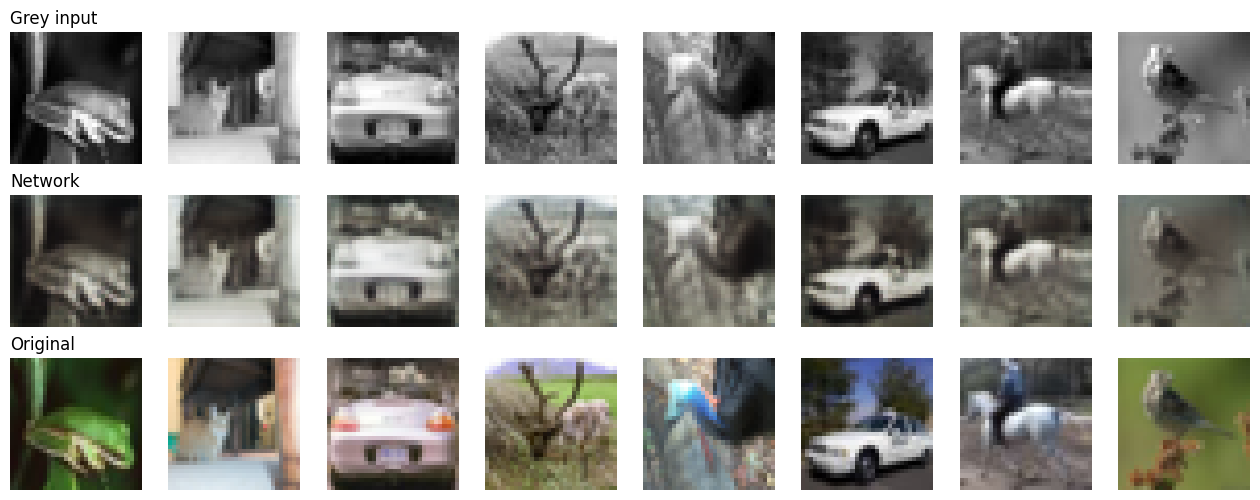

In [8]:
n = 8
predicted = color_model.predict(g_test[:n], verbose=0)

plt.figure(figsize=(2 * n, 6))
for i in range(n):
    # row 1: grey input
    plt.subplot(3, n, i + 1)
    plt.imshow(g_test[i].squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0: plt.title("Grey input", loc="left")

    # row 2: network's colours
    plt.subplot(3, n, n + i + 1)
    plt.imshow(predicted[i])
    plt.axis("off")
    if i == 0: plt.title("Network", loc="left")

    # row 3: real colours
    plt.subplot(3, n, 2 * n + i + 1)
    plt.imshow(x_test[i])
    plt.axis("off")
    if i == 0: plt.title("Original", loc="left")
plt.show()

In [9]:
# The laziest possible colouriser: copy the grey value into R, G and B (no colour at all)
lazy_prediction = np.repeat(g_test, 3, axis=-1)            # (6000, 32, 32, 1) -> (6000, 32, 32, 3)
lazy_mse = np.mean((lazy_prediction - x_test) ** 2)
print("Lazy grey-copy MSE:   ", lazy_mse)
print("Our network test MSE: ", color_test_mse)

Lazy grey-copy MSE:    0.0067498023
Our network test MSE:  0.006900263484567404


In [10]:
import tensorflow as tf

# Convert RGB -> YUV.  Y = brightness (same as our grey images), U and V = colour only
yuv_train = tf.image.rgb_to_yuv(x_train).numpy()
yuv_val   = tf.image.rgb_to_yuv(x_val).numpy()
yuv_test  = tf.image.rgb_to_yuv(x_test).numpy()

y_train, uv_train = yuv_train[..., :1], yuv_train[..., 1:]   # input: Y, target: U and V
y_val,   uv_val   = yuv_val[..., :1],   yuv_val[..., 1:]
y_test,  uv_test  = yuv_test[..., :1],  yuv_test[..., 1:]

print("Brightness:", y_train.shape, " Colour:", uv_train.shape)
print("Same as our grey images?", np.allclose(y_train, g_train, atol=1e-5))

Brightness: (48000, 32, 32, 1)  Colour: (48000, 32, 32, 2)
Same as our grey images? True


In [11]:
keras.utils.set_random_seed(42)
uv_model = keras.Sequential([
    keras.Input(shape=(32, 32, 1)),   # brightness Y
    layers.Conv2D(8, kernel_size=3, strides=2, padding='same', activation='relu'),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu', name='latent'),
    layers.UpSampling2D(size=2),
    layers.Conv2D(2, kernel_size=3, padding='same', activation='tanh'),   # U and V (can be negative)
])
uv_model.compile(optimizer="adam", loss="mse")

uv_history = uv_model.fit(
    y_train, uv_train,                   # input: brightness, target: colour only
    validation_data=(y_val, uv_val),
    epochs=10,
    batch_size=64,
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 0.0036 - val_loss: 0.0036
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - loss: 0.0034 - val_loss: 0.0036
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.0034 - val_loss: 0.0035
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.0034 - val_loss: 0.0035
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.0033 - val_loss: 0.0035
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - loss: 0.0033 - val_loss: 0.0035
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - loss: 0.0033 - val_loss: 0.0034
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - loss: 0.0033 - val_loss: 0.0034
Epoch 9/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.0033 - val_loss: 0.0034
Epoch 10/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.0033 - val_loss: 0.0034


In [12]:
pred_uv = uv_model.predict(y_test, verbose=0)
pred_yuv = np.concatenate([y_test, pred_uv], axis=-1)              # real Y + predicted U, V
pred_rgb = np.clip(tf.image.yuv_to_rgb(pred_yuv).numpy(), 0, 1)    # back to RGB, keep within 0..1

uv_rgb_mse = np.mean((pred_rgb - x_test) ** 2)
print("Lazy grey-copy MSE:      ", lazy_mse)
print("RGB network MSE:         ", color_test_mse)
print("Chrominance network MSE: ", uv_rgb_mse)

Lazy grey-copy MSE:       0.0067498023
RGB network MSE:          0.006900263484567404
Chrominance network MSE:  0.0057621724


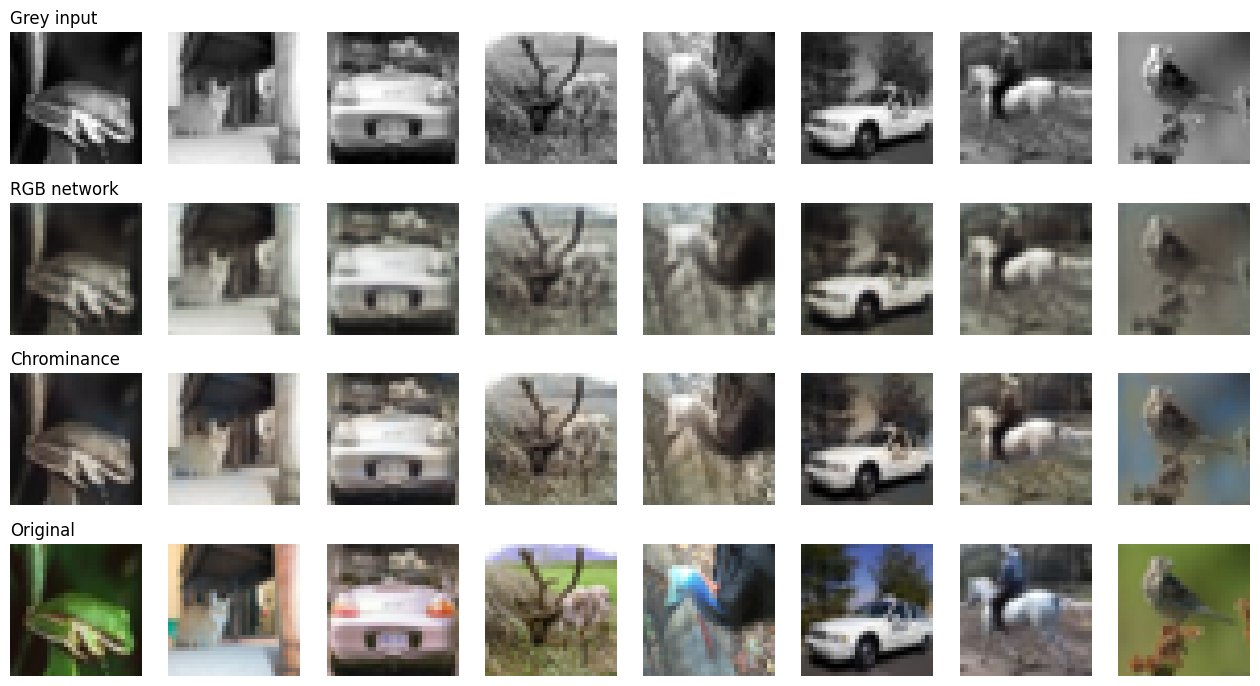

In [13]:
n = 8
pred_rgb_net = color_model.predict(g_test[:n], verbose=0)

rows = [
    ("Grey input",  [g_test[i].squeeze() for i in range(n)], "gray"),
    ("RGB network", [pred_rgb_net[i] for i in range(n)], None),
    ("Chrominance", [pred_rgb[i] for i in range(n)], None),
    ("Original",    [x_test[i] for i in range(n)], None),
]

plt.figure(figsize=(2 * n, 8.5))
for r, (title, images, cmap) in enumerate(rows):
    for i in range(n):
        plt.subplot(len(rows), n, r * n + i + 1)
        plt.imshow(images[i], cmap=cmap)
        plt.axis("off")
        if i == 0: plt.title(title, loc="left")
plt.show()

In [14]:
keras.utils.set_random_seed(42)
big_uv_model = keras.Sequential([
    keras.Input(shape=(32, 32, 1)),   # brightness Y

    # Encoder: more filters, and shrink twice (32 -> 16 -> 8) so each pixel sees more of the image
    layers.Conv2D(16, kernel_size=3, strides=2, padding='same', activation='relu'),   # 16x16
    layers.Conv2D(32, kernel_size=3, strides=2, padding='same', activation='relu'),   # 8x8
    layers.Conv2D(32, kernel_size=3, padding='same', activation='relu', name='latent'),

    # Decoder: grow back twice (8 -> 16 -> 32)
    layers.UpSampling2D(size=2),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu'),
    layers.UpSampling2D(size=2),
    layers.Conv2D(8, kernel_size=3, padding='same', activation='relu'),
    layers.Conv2D(2, kernel_size=3, padding='same', activation='tanh'),   # U and V
])
big_uv_model.compile(optimizer="adam", loss="mse")
big_uv_model.summary()

big_uv_history = big_uv_model.fit(
    y_train, uv_train,
    validation_data=(y_val, uv_val),
    epochs=10,
    batch_size=64,
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Conv2D)                 │ (None, 8, 8, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 32, 32, 8)      │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 32, 2)      │           146 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,978 (78.04 KB)

 Trainable params: 19,978 (78.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 19s 22ms/step - loss: 0.0035 - val_loss: 0.0034
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - loss: 0.0034 - val_loss: 0.0034
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - loss: 0.0033 - val_loss: 0.0033
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - loss: 0.0033 - val_loss: 0.0033
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 17s 22ms/step - loss: 0.0032 - val_loss: 0.0033
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - loss: 0.0032 - val_loss: 0.0032
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - loss: 0.0032 - val_loss: 0.0032
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - loss: 0.0032 - val_loss: 0.0032
Epoch 9/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - loss: 0.0032 - val_loss: 0.0032
Epoch 10/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - loss: 0.0031 - val_loss: 0.0032


In [15]:
pred_uv_big = big_uv_model.predict(y_test, verbose=0)
pred_rgb_big = np.clip(tf.image.yuv_to_rgb(np.concatenate([y_test, pred_uv_big], axis=-1)).numpy(), 0, 1)
big_uv_rgb_mse = np.mean((pred_rgb_big - x_test) ** 2)

print("Lazy grey-copy MSE:          ", lazy_mse)
print("RGB network MSE:             ", color_test_mse)
print("Chrominance network MSE:     ", uv_rgb_mse)
print("Bigger chrominance net MSE:  ", big_uv_rgb_mse)

Lazy grey-copy MSE:           0.0067498023
RGB network MSE:              0.006900263484567404
Chrominance network MSE:      0.0057621724
Bigger chrominance net MSE:   0.0053580254


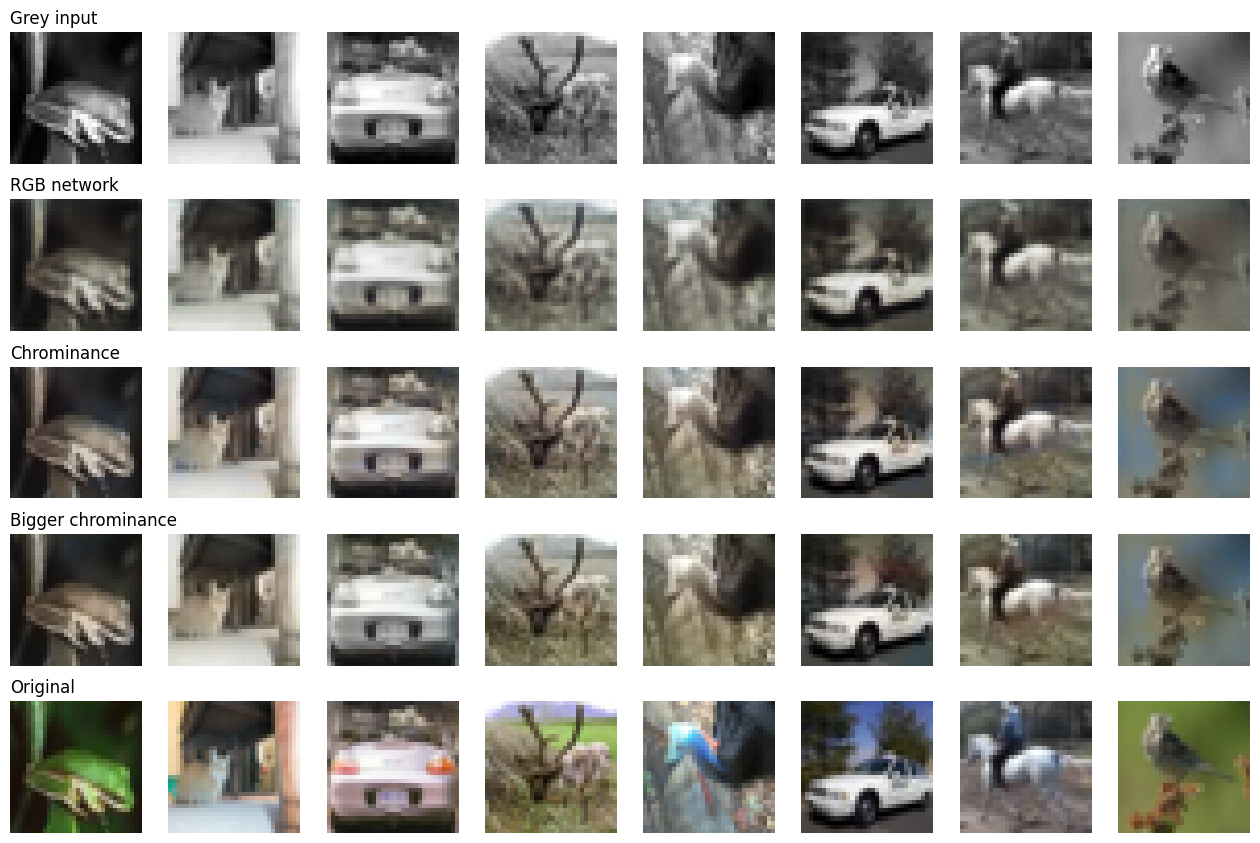

In [16]:
n = 8
rows = [
    ("Grey input",         [g_test[i].squeeze() for i in range(n)], "gray"),
    ("RGB network",        [pred_rgb_net[i] for i in range(n)], None),
    ("Chrominance",        [pred_rgb[i] for i in range(n)], None),
    ("Bigger chrominance", [pred_rgb_big[i] for i in range(n)], None),
    ("Original",           [x_test[i] for i in range(n)], None),
]

plt.figure(figsize=(2 * n, 10.5))
for r, (title, images, cmap) in enumerate(rows):
    for i in range(n):
        plt.subplot(len(rows), n, r * n + i + 1)
        plt.imshow(images[i], cmap=cmap)
        plt.axis("off")
        if i == 0: plt.title(title, loc="left")
plt.show()